In [18]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd()

sys.path.insert(0, str(ROOT))


PosixPath('/home/sakana/Code/ManifoldsTeam/woodbench')

In [ ]:
# Có chủ đích: khi Jupyter được mở ngay trong
# notebooks/phase 1/investigator/, repo root nằm đúng ba cấp cha.
# Cell đầu vẫn giữ convention chung ROOT=Path.cwd(); fallback này chỉ chạy
# khi cwd hiện tại không phải repo root và luôn kiểm tra marker trước khi dùng.
if not (ROOT / 'data').exists():
    notebook_local_root = Path.cwd().parent.parent.parent
    required_markers = [
        notebook_local_root / 'data',
        notebook_local_root / 'notebooks',
        notebook_local_root / 'docs',
    ]
    if not all(marker.exists() for marker in required_markers):
        raise RuntimeError(
            'Không xác định được repo root. Hãy chạy notebook từ repo root '
            'hoặc từ notebooks/phase 1/investigator/.'
        )
    ROOT = notebook_local_root
    sys.path.insert(0, str(ROOT))
    print(f'Local notebook cwd detected; intentionally moved 3 parents to ROOT={ROOT}')


# Phase 1B — Kiểm tra trùng lặp không phụ thuộc tên file

Notebook thực hiện mục 4.1–4.5 bằng hai phép đo độc lập:

1. embedding trước classifier của **Swin-T pretrained ImageNet-1K**, đóng băng hoàn toàn và không fine-tune trên WoodID;
2. perceptual hash DCT 64-bit, không dùng mô hình học sâu.

So sánh đúng hai trạng thái dataset hiện có:

- `original_20`: `data/split`, random split seed 42 dựng từ raw, 20 lớp;
- `strict_17`: `data/task-B-group-split`, split theo `origin_key`, 17 lớp.

> **Caveat:** đây là so sánh hai trạng thái dataset thực tế, không phải controlled ablation chỉ thay cách split, vì class universe đồng thời đổi từ 20 xuống 17 và strict còn đi qua pipeline materialization/dedup riêng. Không được quy toàn bộ delta cho cách split.


In [5]:
if Path('/content').exists():
    !pip install -q -r {ROOT}/requirements.txt


In [6]:
import hashlib
import json
import math
import re
import textwrap
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from matplotlib.ticker import FormatStrFormatter, MultipleLocator
from PIL import Image, ImageOps
from scipy.fft import dctn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import Swin_T_Weights, swin_t

ORIGINAL_ROOT = ROOT / 'data' / 'split'
STRICT_ROOT = ROOT / 'data' / 'task-B-group-split'
ARTIFACT_DIR = ROOT / 'artifacts' / 'phase_1b' / 'visual_duplicate_audit'
MANIFEST_DIR = ARTIFACT_DIR / 'manifests'
EMBEDDING_DIR = ARTIFACT_DIR / 'embeddings'
FIGURE_DIR = ARTIFACT_DIR / 'figures'
TABLE_DIR = ARTIFACT_DIR / 'tables'
for directory in [ARTIFACT_DIR, MANIFEST_DIR, EMBEDDING_DIR, FIGURE_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff', '.webp'}
SPLITS = ('train', 'val', 'test')
DATASETS = {
    'original_20': ORIGINAL_ROOT,
    'strict_17': STRICT_ROOT,
}
EXPECTED_COUNTS = {
    'original_20': {'train': 4487, 'val': 955, 'test': 981, 'classes': 20},
    'strict_17': {'train': 3365, 'val': 903, 'test': 532, 'classes': 17},
}
BATCH_SIZE = 64 if torch.cuda.is_available() else 16
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
SIMILARITY_CHUNK_SIZE = 128
FORCE_RECOMPUTE = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_ID = 'torchvision.swin_t.Swin_T_Weights.IMAGENET1K_V1'
print(f'ROOT={ROOT}')
print(f'DEVICE={DEVICE}; batch_size={BATCH_SIZE}')
print(f'Artifacts={ARTIFACT_DIR.relative_to(ROOT)}')


ROOT=/home/sakana/Code/ManifoldsTeam/woodbench
DEVICE=cuda; batch_size=64
Artifacts=artifacts/phase_1b/visual_duplicate_audit


## 4.0. Xác nhận provenance và tạo manifest

`data/split` không được copy lại: nó đã là original random split được tái tạo từ raw bằng seed 42, dùng symlink hợp lệ. Notebook chỉ ghi manifest vào `artifacts`. Với `data/split`, tên loài là thư mục cha trực tiếp của ảnh dù còn một tầng family; với strict-17, tên loài cũng là thư mục cha trực tiếp.


In [7]:
def infer_origin_key(path):
    stem = path.stem
    stem = re.sub(r'__from-[^_]+__[0-9a-fA-F]{8}$', '', stem)
    stem = re.sub(r'\s*\(\d+\)$', '', stem)
    return f'{path.parent.name}::{stem}'


def collect_manifest(dataset_name, data_root):
    rows = []
    for split in SPLITS:
        split_root = data_root / split
        if not split_root.exists():
            raise FileNotFoundError(split_root)
        for path in sorted(split_root.rglob('*')):
            if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue
            rows.append({
                'dataset': dataset_name,
                'split': split,
                'class_name': path.parent.name,
                'filename': path.name,
                'origin_key': infer_origin_key(path),
                'path': str(path.relative_to(ROOT)),
                'is_symlink': path.is_symlink(),
            })
    return pd.DataFrame(rows).sort_values(
        ['split', 'class_name', 'filename', 'path']
    ).reset_index(drop=True)


def manifest_signature(frame, split):
    paths = frame.loc[frame['split'].eq(split), 'path'].astype(str).tolist()
    return hashlib.sha256('\n'.join(paths).encode('utf-8')).hexdigest()


In [8]:
manifests = {}
dataset_summary_rows = []
original_metadata = json.loads(
    (ORIGINAL_ROOT / 'split_metadata.json').read_text(encoding='utf-8')
)
assert original_metadata['seed'] == 42
assert original_metadata['counts'] == {
    split: EXPECTED_COUNTS['original_20'][split] for split in SPLITS
}
for dataset_name, data_root in DATASETS.items():
    manifest = collect_manifest(dataset_name, data_root)
    manifests[dataset_name] = manifest
    manifest.to_csv(MANIFEST_DIR / f'{dataset_name}.csv', index=False)
    counts = manifest.groupby('split').size().to_dict()
    n_classes = manifest['class_name'].nunique()
    expected = EXPECTED_COUNTS[dataset_name]
    assert all(counts.get(split, 0) == expected[split] for split in SPLITS), (
        dataset_name, counts, expected
    )
    assert n_classes == expected['classes'], (dataset_name, n_classes)
    if dataset_name == 'original_20':
        assert manifest['is_symlink'].all(), (
            'data/split must remain the symlink-based split rebuilt from raw'
        )
    dataset_summary_rows.append({
        'dataset': dataset_name,
        'data_root': str(data_root.relative_to(ROOT)),
        'classes': n_classes,
        'train_images': counts['train'],
        'val_images': counts['val'],
        'test_images': counts['test'],
        'total_images': len(manifest),
        'symlink_images': int(manifest['is_symlink'].sum()),
        'train_signature': manifest_signature(manifest, 'train'),
        'test_signature': manifest_signature(manifest, 'test'),
    })
dataset_summary = pd.DataFrame(dataset_summary_rows)
dataset_summary.to_csv(TABLE_DIR / 'dataset_summary.csv', index=False)
display(dataset_summary)
display(Markdown(
    '**Interpretation guard:** original-20 và strict-17 khác cả cách split, '
    'số lớp và lịch sử materialization; chỉ so sánh trạng thái thực tế, '
    'không quy toàn bộ delta cho origin grouping.'
))


,dataset,data_root,classes,train_images,val_images,test_images,total_images,symlink_images,train_signature,test_signature
0,original_20,data/split,20,4487,955,981,6423,6423,1a0dd71d4aac3cb80192028e9285b4ddaaf17b399c68ce...,197be190a84a97dd832969287cf3e62e63782c4c7dfe11...
1,strict_17,data/task-B-group-split,17,3365,903,532,4800,0,ce351ac13f33b6dad42caaa18c607c34a5e16962175e61...,97159fc9627ede6f14ad71c0e45297fdd6789d1822a9d9...


**Interpretation guard:** original-20 và strict-17 khác cả cách split, số lớp và lịch sử materialization; chỉ so sánh trạng thái thực tế, không quy toàn bộ delta cho origin grouping.

## 4.1. Swin-T ImageNet-1K chưa từng train trên WoodID

Cell dưới đây chỉ tải official torchvision weights `IMAGENET1K_V1`, thay `head` bằng `Identity`, đặt `eval()` và tắt gradient. Không có đường dẫn nào tới `data/experiments` và không có optimizer/training loop. Vector đầu ra 768 chiều là vector ngay trước classifier gốc.


In [9]:
weights = Swin_T_Weights.IMAGENET1K_V1
transform = weights.transforms()
model = swin_t(weights=weights)
classifier_in_features = model.head.in_features
model.head = nn.Identity()
model.eval().to(DEVICE)
for parameter in model.parameters():
    parameter.requires_grad_(False)
assert classifier_in_features == 768
assert not any(parameter.requires_grad for parameter in model.parameters())
model_provenance = {
    'model_id': MODEL_ID,
    'weights_url': weights.url,
    'feature_dimension': classifier_in_features,
    'classifier_replacement': 'nn.Identity',
    'training_on_woodid': False,
    'experiment_checkpoint_loaded': False,
    'eval_mode': not model.training,
}
(ARTIFACT_DIR / 'model_provenance.json').write_text(
    json.dumps(model_provenance, indent=2), encoding='utf-8'
)
display(model_provenance)


Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /home/sakana/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:01<00:00, 102MB/s]  


{'model_id': 'torchvision.swin_t.Swin_T_Weights.IMAGENET1K_V1',
 'weights_url': 'https://download.pytorch.org/models/swin_t-704ceda3.pth',
 'feature_dimension': 768,
 'classifier_replacement': 'nn.Identity',
 'training_on_woodid': False,
 'experiment_checkpoint_loaded': False,
 'eval_mode': True}

In [10]:
class ManifestImageDataset(Dataset):
    def __init__(self, frame, image_transform):
        self.frame = frame.reset_index(drop=True)
        self.image_transform = image_transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        path = ROOT / self.frame.iloc[index]['path']
        with Image.open(path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
            tensor = self.image_transform(image)
        return tensor, index


def extract_embeddings(frame, dataset_name, split):
    split_frame = frame[frame['split'].eq(split)].reset_index(drop=True)
    output_path = EMBEDDING_DIR / f'{dataset_name}_{split}_swin_t_imagenet1k_v1.npy'
    metadata_path = output_path.with_suffix('.json')
    signature = manifest_signature(frame, split)
    if output_path.exists() and metadata_path.exists() and not FORCE_RECOMPUTE:
        metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
        cached = np.load(output_path)
        if (
            metadata.get('manifest_signature') == signature
            and metadata.get('model_id') == MODEL_ID
            and cached.shape == (len(split_frame), classifier_in_features)
        ):
            print(f'Loaded cache: {output_path.relative_to(ROOT)}')
            return split_frame, cached
    loader = DataLoader(
        ManifestImageDataset(split_frame, transform),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )
    batches = []
    with torch.inference_mode():
        for batch_index, (images, indices) in enumerate(loader, start=1):
            features = model(images.to(DEVICE, non_blocking=True))
            features = torch.nn.functional.normalize(features, dim=1)
            batches.append(features.cpu().numpy().astype(np.float32))
            if batch_index % 25 == 0 or batch_index == len(loader):
                print(f'{dataset_name}/{split}: {batch_index}/{len(loader)} batches')
    embeddings = np.concatenate(batches, axis=0)
    np.save(output_path, embeddings)
    metadata_path.write_text(json.dumps({
        'dataset': dataset_name, 'split': split, 'rows': len(split_frame),
        'feature_dimension': classifier_in_features, 'model_id': MODEL_ID,
        'manifest_signature': signature,
    }, indent=2), encoding='utf-8')
    return split_frame, embeddings


## 4.2–4.3. Max cosine similarity từ test tới train

Với mỗi ảnh test `i`, notebook tính `m_i = max_j cosine(test_i, train_j)`. Hai cột `% > 0.90` và `% > 0.95` lần lượt là:

```text
100 × số ảnh test có m_i > ngưỡng / tổng số ảnh test
```

Ví dụ `77,17% > 0,90` của original-20 nghĩa là 757/981 ảnh test có ít nhất một ảnh train đạt cosine similarity lớn hơn 0,90. Đây không phải phần trăm dự đoán đúng và không phải confidence của classifier.


In [11]:
def nearest_by_cosine(train_embeddings, test_embeddings):
    best_scores = np.empty(len(test_embeddings), dtype=np.float32)
    best_indices = np.empty(len(test_embeddings), dtype=np.int64)
    train_tensor = torch.from_numpy(train_embeddings).to(DEVICE)
    for start in range(0, len(test_embeddings), SIMILARITY_CHUNK_SIZE):
        stop = min(start + SIMILARITY_CHUNK_SIZE, len(test_embeddings))
        test_tensor = torch.from_numpy(test_embeddings[start:stop]).to(DEVICE)
        similarities = test_tensor @ train_tensor.T
        values, indices = similarities.max(dim=1)
        best_scores[start:stop] = values.cpu().numpy()
        best_indices[start:stop] = indices.cpu().numpy()
    return best_scores, best_indices


embedding_results = {}
embedding_summary_rows = []
for dataset_name, manifest in manifests.items():
    train_frame, train_embeddings = extract_embeddings(manifest, dataset_name, 'train')
    test_frame, test_embeddings = extract_embeddings(manifest, dataset_name, 'test')
    max_similarity, train_index = nearest_by_cosine(train_embeddings, test_embeddings)
    result = test_frame.add_prefix('test_').copy()
    nearest_train = train_frame.iloc[train_index].reset_index(drop=True).add_prefix('train_')
    result = pd.concat([result.reset_index(drop=True), nearest_train], axis=1)
    result.insert(0, 'max_cosine_similarity', max_similarity)
    result.insert(1, 'same_class', result['test_class_name'].eq(result['train_class_name']))
    result = result.sort_values('max_cosine_similarity', ascending=False).reset_index(drop=True)
    result.insert(0, 'rank', np.arange(1, len(result) + 1))
    result.to_csv(TABLE_DIR / f'{dataset_name}_embedding_nearest_neighbors.csv', index=False)
    embedding_results[dataset_name] = result
    embedding_summary_rows.append({
        'dataset': dataset_name,
        'classes': manifest['class_name'].nunique(),
        'train_images': len(train_frame),
        'test_images': len(test_frame),
        'mean_max_similarity': float(max_similarity.mean()),
        'median_max_similarity': float(np.median(max_similarity)),
        'p95_max_similarity': float(np.quantile(max_similarity, 0.95)),
        'pct_above_0_90': float((max_similarity > 0.90).mean() * 100),
        'pct_above_0_95': float((max_similarity > 0.95).mean() * 100),
        'pct_nearest_same_class': float(result['same_class'].mean() * 100),
    })
embedding_summary = pd.DataFrame(embedding_summary_rows)
embedding_summary.to_csv(TABLE_DIR / 'embedding_threshold_summary.csv', index=False)
display(embedding_summary)


original_20/train: 25/71 batches
original_20/train: 50/71 batches
original_20/train: 71/71 batches
original_20/test: 16/16 batches
strict_17/train: 25/53 batches
strict_17/train: 50/53 batches
strict_17/train: 53/53 batches
strict_17/test: 9/9 batches


,dataset,classes,train_images,test_images,mean_max_similarity,median_max_similarity,p95_max_similarity,pct_above_0_90,pct_above_0_95,pct_nearest_same_class
0,original_20,20,4487,981,0.926002,0.930909,1.000000,77.166157,27.420999,98.674822
1,strict_17,17,3365,532,0.903423,0.912677,0.963608,63.345865,14.285714,93.796992


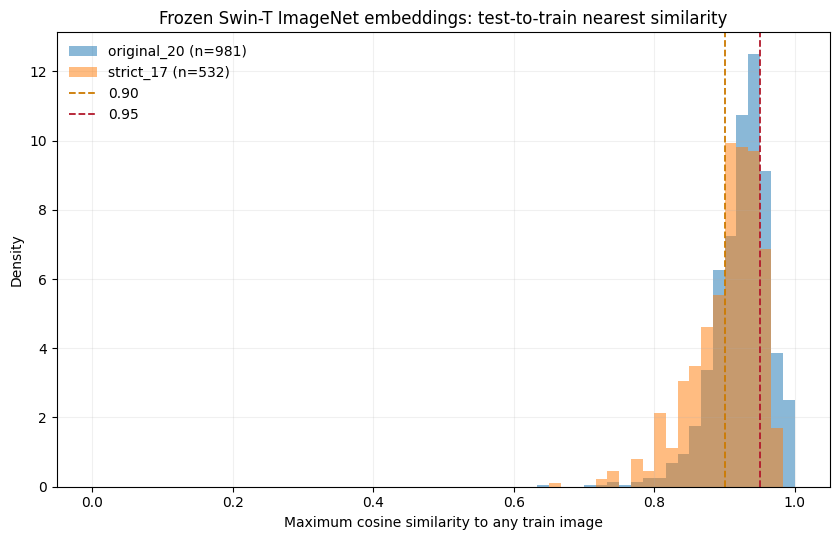

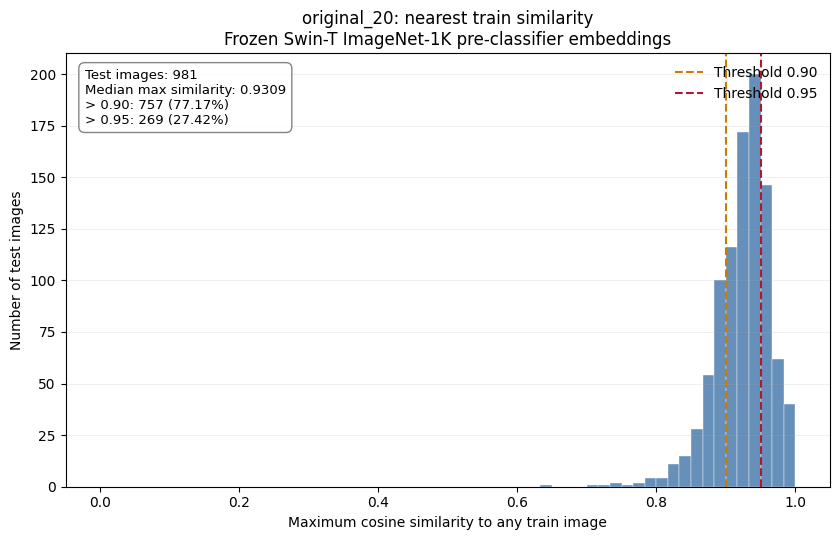

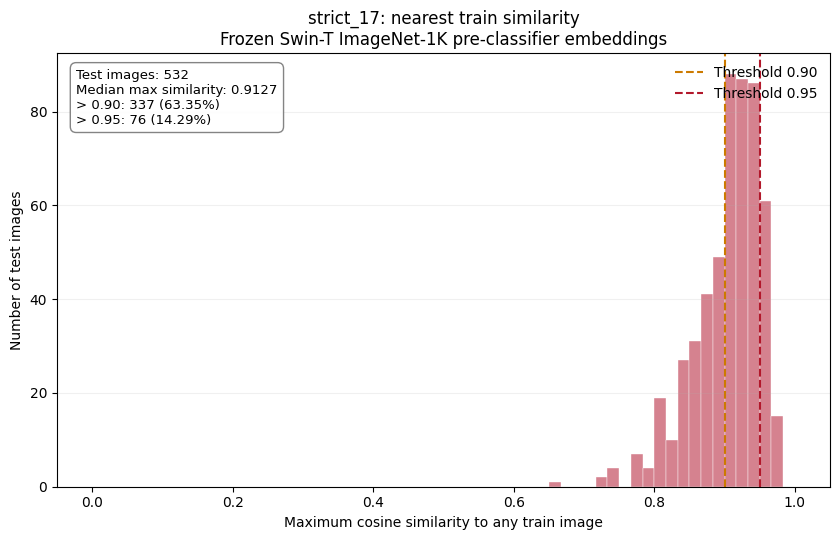

In [19]:
all_scores = np.concatenate([
    frame['max_cosine_similarity'].to_numpy()
    for frame in embedding_results.values()
])
lower = min(0.0, math.floor(float(all_scores.min()) * 20) / 20)
bins = np.linspace(lower, 1.0, 61)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for dataset_name, frame in embedding_results.items():
    ax.hist(
        frame['max_cosine_similarity'], bins=bins, alpha=0.52, density=True,
        label=f"{dataset_name} (n={len(frame)})",
    )
ax.axvline(0.90, color='#cc7a00', linestyle='--', linewidth=1.3, label='0.90')
ax.axvline(0.95, color='#b2182b', linestyle='--', linewidth=1.3, label='0.95')
ax.set_xlabel('Maximum cosine similarity to any train image')
ax.set_ylabel('Density')
ax.set_title('Frozen Swin-T ImageNet embeddings: test-to-train nearest similarity')
ax.legend(frameon=False)
ax.grid(alpha=0.18)
fig.tight_layout()
embedding_histogram_path = FIGURE_DIR / 'embedding_max_similarity_histogram.png'
fig.savefig(embedding_histogram_path, dpi=300, bbox_inches='tight')
plt.show()

dataset_colors = {
    'original_20': '#4477AA',
    'strict_17': '#CC6677',
}
individual_embedding_histograms = {}
for dataset_name, frame in embedding_results.items():
    scores = frame['max_cosine_similarity'].to_numpy()
    count_above_090 = int((scores > 0.90).sum())
    count_above_095 = int((scores > 0.95).sum())
    pct_above_090 = count_above_090 / len(scores) * 100
    pct_above_095 = count_above_095 / len(scores) * 100
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    bin_counts, bin_edges, bar_patches = ax.hist(
        scores, bins=bins, color=dataset_colors[dataset_name],
        alpha=0.82, edgecolor='white', linewidth=0.35,
    )
    max_bin_count = float(bin_counts.max())
    for count, patch in zip(bin_counts, bar_patches):
        if count <= 0:
            continue
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            patch.get_height() + max_bin_count * 0.012,
            f'{int(count)}', ha='center', va='bottom',
            fontsize=5.8, rotation=90, color='#333333',
        )
    ax.axvline(0.90, color='#cc7a00', linestyle='--', linewidth=1.5, label='Threshold 0.90')
    ax.axvline(0.95, color='#b2182b', linestyle='--', linewidth=1.5, label='Threshold 0.95')
    median_score = float(np.median(scores))
    ax.axvline(
        median_score, color='#228833', linestyle='-.', linewidth=1.4,
        label=f'Median {median_score:.4f}',
    )
    annotation = (
        f"Test images: {len(scores):,}\n"
        f"Median max similarity: {median_score:.4f}\n"
        f"> 0.90: {count_above_090:,} ({pct_above_090:.2f}%)\n"
        f"> 0.95: {count_above_095:,} ({pct_above_095:.2f}%)"
    )
    ax.text(
        0.025, 0.965, annotation, transform=ax.transAxes, va='top', ha='left',
        fontsize=9.5, bbox={'boxstyle': 'round,pad=0.45', 'facecolor': 'white', 'alpha': 0.9, 'edgecolor': '#777777'},
    )
    ax.set_xlabel('Maximum cosine similarity to any train image')
    ax.set_ylabel('Number of test images')
    x_lower = max(0.0, math.floor(float(scores.min()) * 20) / 20)
    ax.set_xlim(x_lower, 1.005)
    ax.set_ylim(0, max_bin_count * 1.16)
    ax.xaxis.set_major_locator(MultipleLocator(0.05))
    ax.xaxis.set_minor_locator(MultipleLocator(0.01))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.tick_params(axis='x', which='major', labelsize=9, rotation=35)
    ax.tick_params(axis='x', which='minor', length=3, color='#777777')
    ax.set_title(
        f'{dataset_name}: nearest train similarity\n'
        'Frozen Swin-T ImageNet-1K pre-classifier embeddings'
    )
    ax.legend(frameon=False, loc='upper right')
    ax.grid(axis='y', alpha=0.20)
    ax.grid(axis='x', which='major', alpha=0.14, linestyle=':')
    fig.tight_layout()
    output_path = FIGURE_DIR / f'{dataset_name}_embedding_max_similarity_histogram.png'
    fig.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    individual_embedding_histograms[dataset_name] = output_path
    plt.show()


## 4.4. Hai mươi cặp embedding gần nhất — lưới 300 DPI

Mỗi cặp gồm ảnh train bên trái và ảnh test bên phải; nhãn ghi similarity, class, filename và `origin_key`. Figure caption được đặt trong chính ảnh để artifact dùng độc lập vẫn giữ provenance.


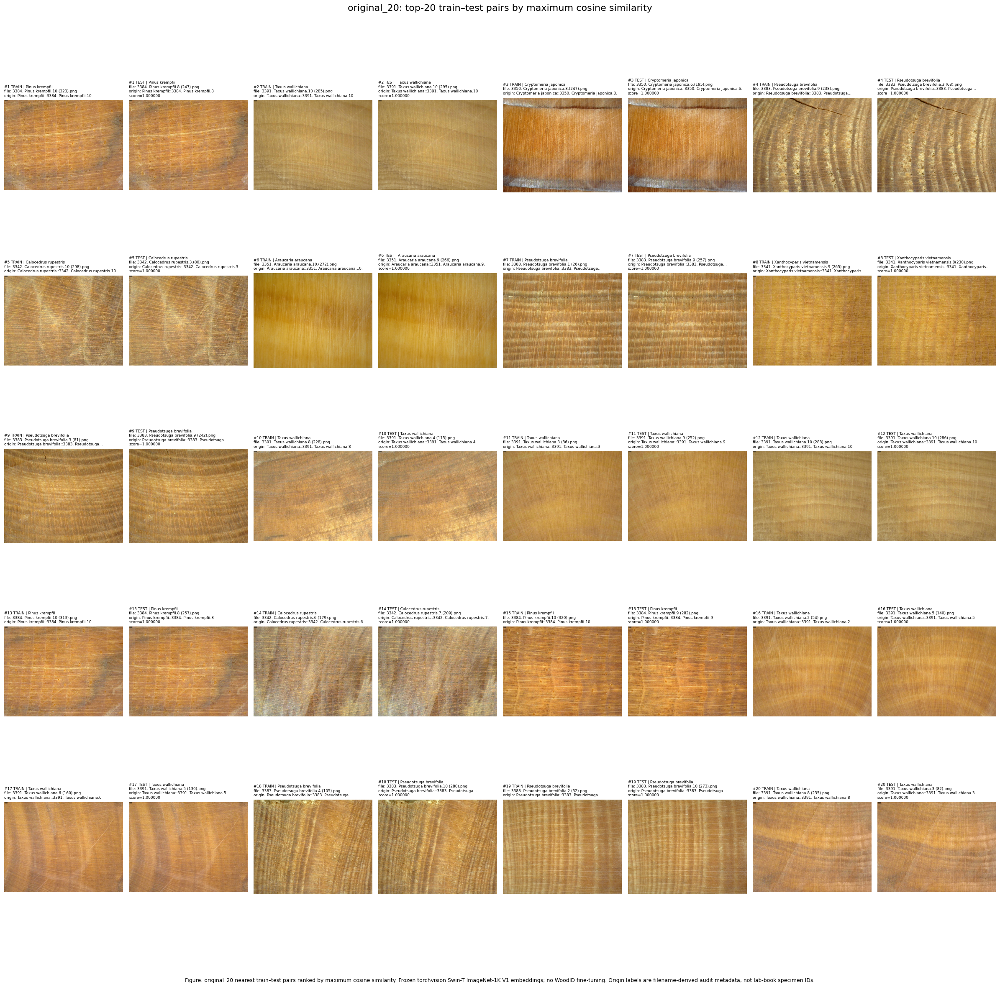

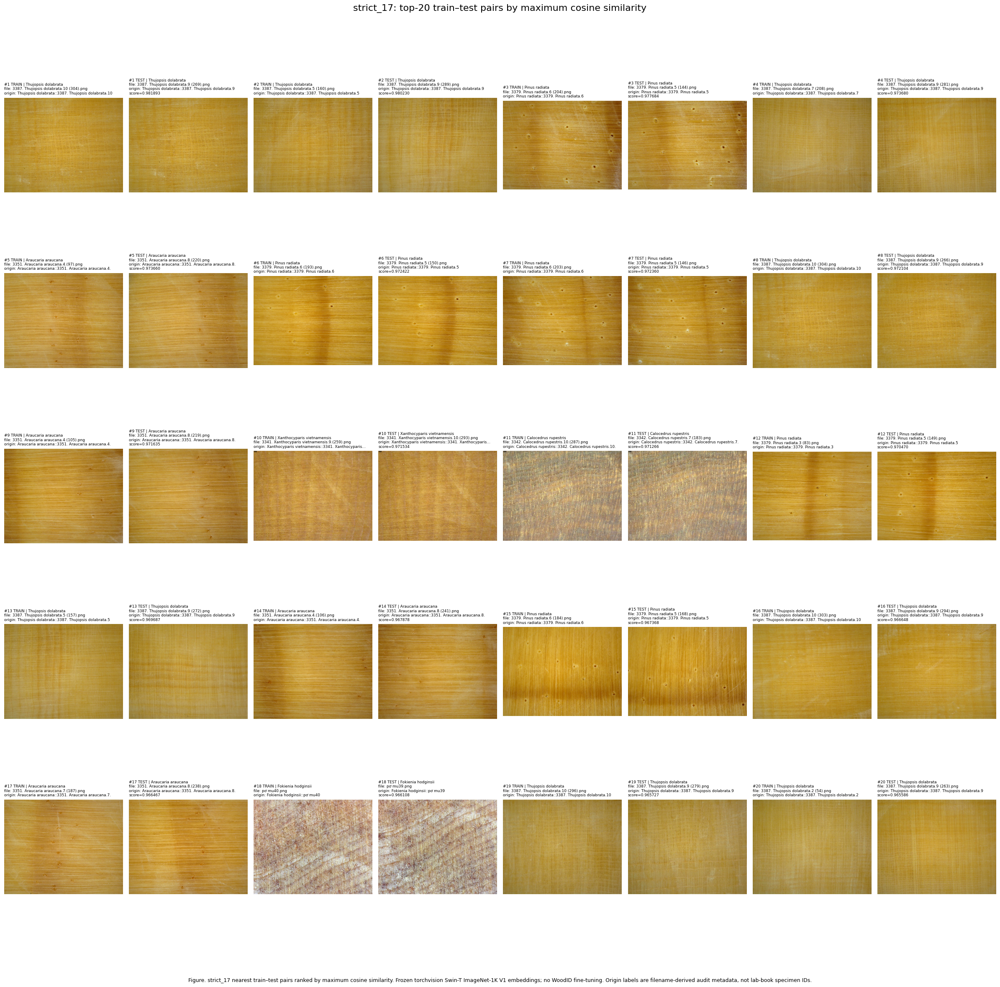

In [13]:
def short_label(text, width=52):
    return textwrap.shorten(str(text), width=width, placeholder='…')


def make_pair_grid(frame, dataset_name, score_column, output_path, method_label):
    top = frame.sort_values(score_column, ascending=False).head(20).reset_index(drop=True)
    pairs_per_row = 4
    rows = math.ceil(len(top) / pairs_per_row)
    fig, axes = plt.subplots(rows, pairs_per_row * 2, figsize=(24, rows * 4.7))
    axes = np.asarray(axes).reshape(rows, pairs_per_row * 2)
    for axis in axes.flat:
        axis.axis('off')
    for rank, row in top.iterrows():
        grid_row = rank // pairs_per_row
        pair_col = (rank % pairs_per_row) * 2
        for offset, side in enumerate(('train', 'test')):
            axis = axes[grid_row, pair_col + offset]
            path = ROOT / row[f'{side}_path']
            with Image.open(path) as image:
                image = ImageOps.exif_transpose(image).convert('RGB')
                axis.imshow(image)
            title = (
                f"#{rank + 1} {side.upper()} | {short_label(row[f'{side}_class_name'], 30)}\n"
                f"file: {short_label(row[f'{side}_filename'])}\n"
                f"origin: {short_label(row[f'{side}_origin_key'])}"
            )
            if side == 'test':
                title += f"\nscore={row[score_column]:.6f}"
            axis.set_title(title, fontsize=6.5, loc='left')
            axis.axis('off')
    fig.suptitle(
        f'{dataset_name}: top-20 train–test pairs by {method_label}',
        fontsize=16, y=0.998,
    )
    method_provenance = (
        'Frozen torchvision Swin-T ImageNet-1K V1 embeddings; no WoodID fine-tuning.'
        if 'cosine' in method_label.lower()
        else 'Non-learning-based 64-bit DCT perceptual hash; no model weights.'
    )
    caption = (
        f'Figure. {dataset_name} nearest train–test pairs ranked by {method_label}. '
        f'{method_provenance} Origin labels are filename-derived audit metadata, '
        'not lab-book specimen IDs.'
    )
    fig.text(0.5, 0.002, caption, ha='center', va='bottom', fontsize=9, wrap=True)
    fig.tight_layout(rect=(0, 0.025, 1, 0.985))
    fig.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    return top


embedding_top20 = {}
for dataset_name, frame in embedding_results.items():
    output_path = FIGURE_DIR / f'{dataset_name}_top20_embedding_pairs_300dpi.png'
    top = make_pair_grid(
        frame, dataset_name, 'max_cosine_similarity', output_path,
        'maximum cosine similarity',
    )
    top.to_csv(TABLE_DIR / f'{dataset_name}_top20_embedding_pairs.csv', index=False)
    embedding_top20[dataset_name] = top


## 4.5. Perceptual hash độc lập với embedding

pHash chuyển ảnh sang grayscale 32×32, tính DCT hai chiều, lấy khối tần số thấp 8×8 và nhị phân hóa quanh median thành 64 bit. Khoảng cách Hamming càng nhỏ thì ảnh càng giống về cấu trúc thị giác. Báo cáo tỷ lệ test có nearest-train distance bằng 0, ≤4 và ≤8.


In [20]:
def perceptual_hash64(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert('L')
        image = image.resize((32, 32), Image.Resampling.LANCZOS)
        pixels = np.asarray(image, dtype=np.float32)
    low_frequency = dctn(pixels, type=2, norm='ortho')[:8, :8]
    threshold = np.median(low_frequency.reshape(-1)[1:])
    bits = (low_frequency >= threshold).reshape(-1)
    packed = np.packbits(bits.astype(np.uint8), bitorder='big')
    return np.frombuffer(packed.tobytes(), dtype='>u8')[0].astype(np.uint64)


def compute_phashes(frame, dataset_name, split):
    split_frame = frame[frame['split'].eq(split)].reset_index(drop=True)
    output_path = TABLE_DIR / f'{dataset_name}_{split}_phash64.csv'
    signature = manifest_signature(frame, split)
    if output_path.exists() and not FORCE_RECOMPUTE:
        cached = pd.read_csv(output_path)
        if (
            len(cached) == len(split_frame)
            and cached['manifest_signature'].eq(signature).all()
        ):
            values = cached['phash_hex'].map(lambda value: int(value, 16)).to_numpy(dtype=np.uint64)
            print(f'Loaded pHash cache: {output_path.relative_to(ROOT)}')
            return split_frame, values
    values = np.array([
        perceptual_hash64(ROOT / path) for path in split_frame['path']
    ], dtype=np.uint64)
    pd.DataFrame({
        'path': split_frame['path'],
        'phash_hex': [f'{int(value):016x}' for value in values],
        'manifest_signature': signature,
    }).to_csv(output_path, index=False)
    return split_frame, values


POPCOUNT = np.array([int(value).bit_count() for value in range(256)], dtype=np.uint8)


def nearest_by_phash(train_hashes, test_hashes, chunk_size=128):
    best_distances = np.empty(len(test_hashes), dtype=np.uint8)
    best_indices = np.empty(len(test_hashes), dtype=np.int64)
    for start in range(0, len(test_hashes), chunk_size):
        stop = min(start + chunk_size, len(test_hashes))
        xor = np.bitwise_xor(test_hashes[start:stop, None], train_hashes[None, :])
        byte_view = xor.view(np.uint8).reshape(stop - start, len(train_hashes), 8)
        distances = POPCOUNT[byte_view].sum(axis=2)
        indices = distances.argmin(axis=1)
        best_indices[start:stop] = indices
        best_distances[start:stop] = distances[np.arange(stop - start), indices]
    return best_distances, best_indices


Loaded pHash cache: artifacts/phase_1b/visual_duplicate_audit/tables/original_20_train_phash64.csv
Loaded pHash cache: artifacts/phase_1b/visual_duplicate_audit/tables/original_20_test_phash64.csv
Loaded pHash cache: artifacts/phase_1b/visual_duplicate_audit/tables/strict_17_train_phash64.csv
Loaded pHash cache: artifacts/phase_1b/visual_duplicate_audit/tables/strict_17_test_phash64.csv


,dataset,classes,train_images,test_images,median_min_hamming_distance,pct_distance_eq_0,pct_distance_le_4,pct_distance_le_8,pct_nearest_same_class
0,original_20,20,4487,981,16.0,6.014271,6.014271,7.135576,18.348624
1,strict_17,17,3365,532,16.0,0.000000,0.000000,0.375940,11.090226


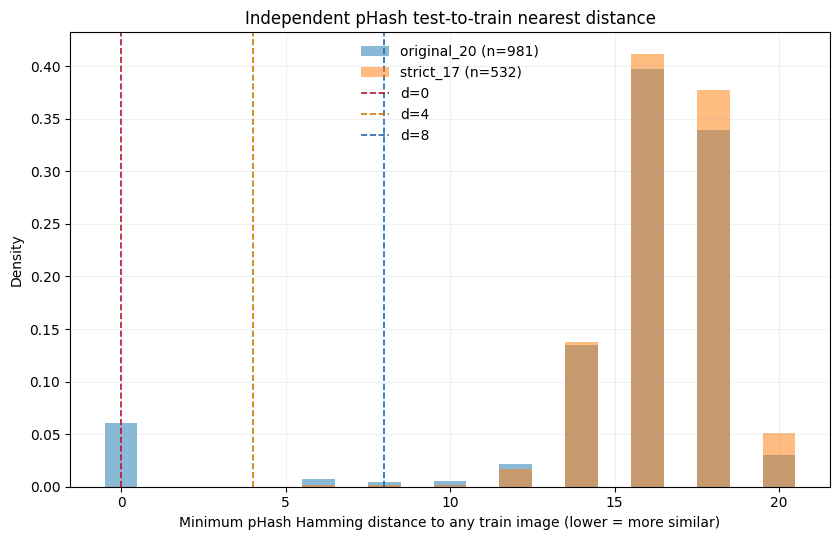

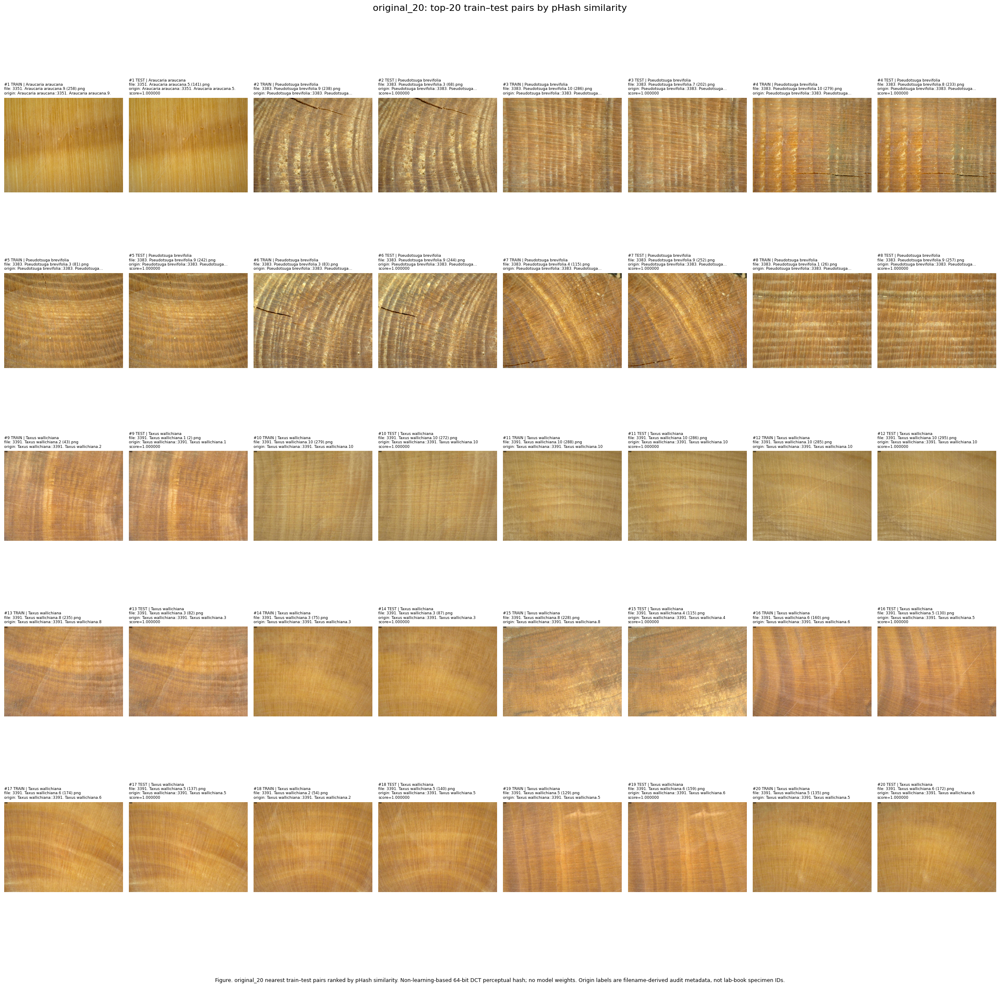

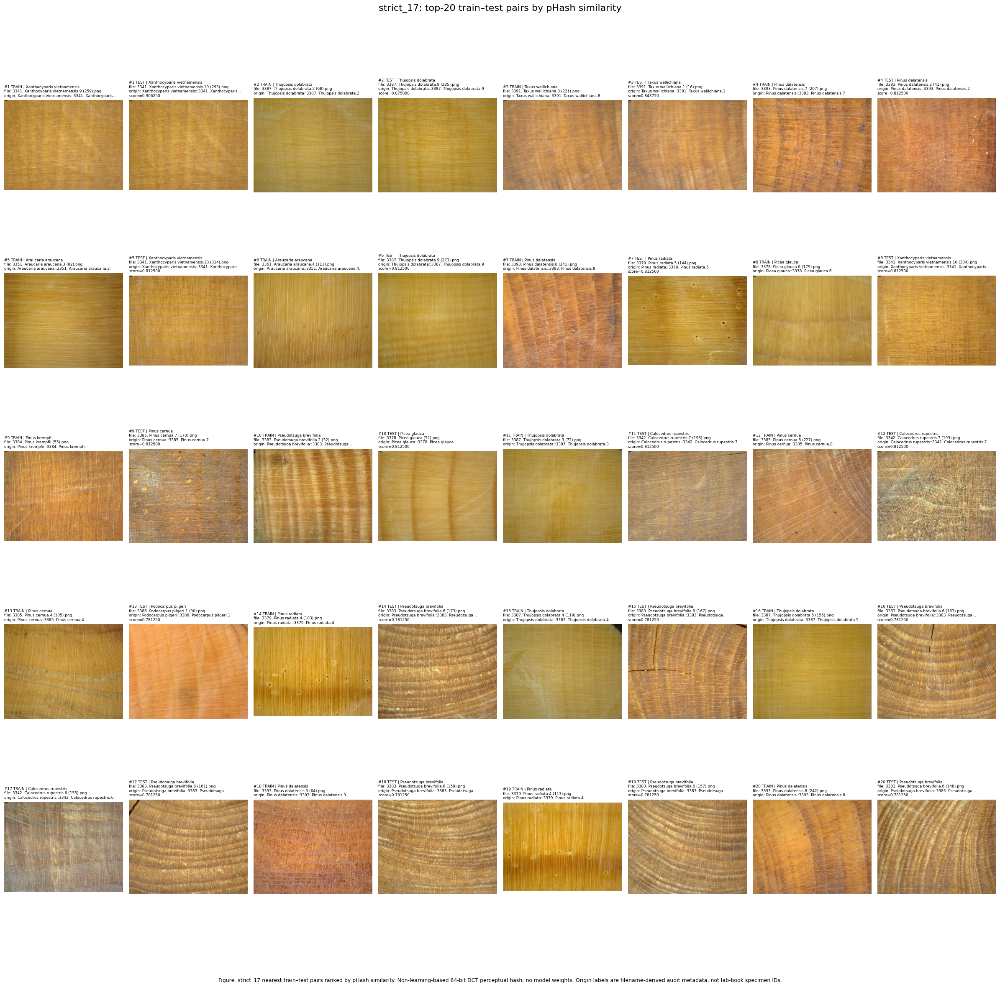

In [21]:
phash_results = {}
phash_summary_rows = []
for dataset_name, manifest in manifests.items():
    train_frame, train_hashes = compute_phashes(manifest, dataset_name, 'train')
    test_frame, test_hashes = compute_phashes(manifest, dataset_name, 'test')
    min_distance, train_index = nearest_by_phash(train_hashes, test_hashes)
    similarity = 1.0 - min_distance.astype(np.float32) / 64.0
    result = test_frame.add_prefix('test_').copy()
    nearest_train = train_frame.iloc[train_index].reset_index(drop=True).add_prefix('train_')
    result = pd.concat([result.reset_index(drop=True), nearest_train], axis=1)
    result.insert(0, 'phash_similarity', similarity)
    result.insert(1, 'min_hamming_distance', min_distance)
    result.insert(2, 'same_class', result['test_class_name'].eq(result['train_class_name']))
    result = result.sort_values(
        ['min_hamming_distance', 'phash_similarity'], ascending=[True, False]
    ).reset_index(drop=True)
    result.insert(0, 'rank', np.arange(1, len(result) + 1))
    result.to_csv(TABLE_DIR / f'{dataset_name}_phash_nearest_neighbors.csv', index=False)
    phash_results[dataset_name] = result
    phash_summary_rows.append({
        'dataset': dataset_name,
        'classes': manifest['class_name'].nunique(),
        'train_images': len(train_frame),
        'test_images': len(test_frame),
        'median_min_hamming_distance': float(np.median(min_distance)),
        'pct_distance_eq_0': float((min_distance == 0).mean() * 100),
        'pct_distance_le_4': float((min_distance <= 4).mean() * 100),
        'pct_distance_le_8': float((min_distance <= 8).mean() * 100),
        'pct_nearest_same_class': float(result['same_class'].mean() * 100),
    })
phash_summary = pd.DataFrame(phash_summary_rows)
phash_summary.to_csv(TABLE_DIR / 'phash_threshold_summary.csv', index=False)
display(phash_summary)

max_distance = max(int(frame['min_hamming_distance'].max()) for frame in phash_results.values())
bins = np.arange(-0.5, max_distance + 1.5, 1)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for dataset_name, frame in phash_results.items():
    ax.hist(
        frame['min_hamming_distance'], bins=bins, alpha=0.52, density=True,
        label=f"{dataset_name} (n={len(frame)})",
    )
for threshold, color in [(0, '#b2182b'), (4, '#cc7a00'), (8, '#2166ac')]:
    ax.axvline(threshold, color=color, linestyle='--', linewidth=1.2, label=f'd={threshold}')
ax.set_xlabel('Minimum pHash Hamming distance to any train image (lower = more similar)')
ax.set_ylabel('Density')
ax.set_title('Independent pHash test-to-train nearest distance')
ax.legend(frameon=False)
ax.grid(alpha=0.18)
fig.tight_layout()
phash_histogram_path = FIGURE_DIR / 'phash_min_distance_histogram.png'
fig.savefig(phash_histogram_path, dpi=300, bbox_inches='tight')
plt.show()

for dataset_name, frame in phash_results.items():
    output_path = FIGURE_DIR / f'{dataset_name}_top20_phash_pairs_300dpi.png'
    top = make_pair_grid(
        frame, dataset_name, 'phash_similarity', output_path, 'pHash similarity',
    )
    top.to_csv(TABLE_DIR / f'{dataset_name}_top20_phash_pairs.csv', index=False)


## Cách đọc và giới hạn kết luận

- Nếu strict-17 vẫn có histogram embedding dồn sát 1 và nhiều pHash distance rất thấp tương tự original-20, đây là bằng chứng độc lập rằng grouping theo tên chưa loại được quan hệ thị giác train–test.
- Nếu strict-17 dịch chuyển similarity xuống và pHash distance lên, kết quả ủng hộ strict split đã giảm trùng lặp thị giác.
- Hai phép đo phải được đọc cùng top-20 grids; similarity cao không tự động đồng nghĩa exact duplicate.
- Vì original có 20 lớp còn strict có 17 lớp và nguồn ảnh sau materialization khác nhau, không dùng delta giữa hai hàng như causal estimate thuần của cách split.
- `origin_key` trong caption chỉ là metadata suy từ filename; không được gọi là specimen ID khi chưa có sổ lab.


In [16]:
run_summary = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'model': model_provenance,
    'datasets': dataset_summary.to_dict(orient='records'),
    'embedding_thresholds': embedding_summary.to_dict(orient='records'),
    'phash_thresholds': phash_summary.to_dict(orient='records'),
    'comparison_caveat': (
        'original_20 and strict_17 differ in split policy, class universe, and '
        'materialization history; delta is descriptive, not a controlled causal effect.'
    ),
}
figure_captions = pd.DataFrame([
    {
        'figure': 'embedding_max_similarity_histogram.png',
        'caption': (
            'Distribution of each test image maximum cosine similarity to the '
            'training set using frozen ImageNet-1K Swin-T pre-classifier embeddings. '
            'Original uses 20 classes; strict uses 17 classes.'
        ),
    },
    {
        'figure': 'phash_min_distance_histogram.png',
        'caption': (
            'Distribution of each test image minimum 64-bit DCT perceptual-hash '
            'Hamming distance to the training set; lower values indicate greater '
            'perceptual similarity.'
        ),
    },
    {
        'figure': 'original_20_embedding_max_similarity_histogram.png',
        'caption': (
            'Original random split (20 classes): distribution of test-to-train '
            'nearest cosine similarity using frozen ImageNet-1K Swin-T embeddings; '
            'orange/red lines mark 0.90/0.95 and the green line marks the median.'
        ),
    },
    {
        'figure': 'strict_17_embedding_max_similarity_histogram.png',
        'caption': (
            'Strict origin split (17 classes): distribution of test-to-train nearest '
            'cosine similarity using frozen ImageNet-1K Swin-T embeddings; orange/red '
            'lines mark 0.90/0.95 and the green line marks the median.'
        ),
    },
] + [
    {
        'figure': f'{dataset_name}_top20_embedding_pairs_300dpi.png',
        'caption': (
            f'Top 20 {dataset_name} train-test pairs ranked by cosine similarity '
            'from frozen ImageNet-1K Swin-T embeddings. Train is shown left and test '
            'right; filenames and filename-derived origin keys are reported.'
        ),
    }
    for dataset_name in DATASETS
] + [
    {
        'figure': f'{dataset_name}_top20_phash_pairs_300dpi.png',
        'caption': (
            f'Top 20 {dataset_name} train-test pairs ranked by 64-bit DCT pHash '
            'similarity, an independent non-learning-based duplicate check.'
        ),
    }
    for dataset_name in DATASETS
])
figure_captions.to_csv(TABLE_DIR / 'figure_captions.csv', index=False)
(ARTIFACT_DIR / 'run_summary.json').write_text(
    json.dumps(run_summary, indent=2, ensure_ascii=False), encoding='utf-8'
)
readme = f'''# Visual duplicate audit artifacts

Generated by `notebooks/phase 1/investigator/WoodID_Phase1_Visual_Duplicate_Audit.ipynb`.

- Original dataset: `data/split` — 20 classes, {EXPECTED_COUNTS['original_20']['train']}/{EXPECTED_COUNTS['original_20']['val']}/{EXPECTED_COUNTS['original_20']['test']} train/val/test.
- Strict dataset: `data/task-B-group-split` — 17 classes, {EXPECTED_COUNTS['strict_17']['train']}/{EXPECTED_COUNTS['strict_17']['val']}/{EXPECTED_COUNTS['strict_17']['test']} train/val/test.
- Embedding: `{MODEL_ID}`, frozen, pre-classifier 768-D vector, no WoodID checkpoint.
- Independent check: DCT pHash 64-bit.
- Figures are exported at 300 DPI.

Important: the two datasets also differ in class universe and materialization history. Treat the comparison as descriptive, not a controlled causal estimate of split policy.
'''
(ARTIFACT_DIR / 'README.md').write_text(readme, encoding='utf-8')
print(f'Completed. Artifacts: {ARTIFACT_DIR.relative_to(ROOT)}')
for path in sorted(ARTIFACT_DIR.rglob('*')):
    if path.is_file():
        print(path.relative_to(ROOT))


Completed. Artifacts: artifacts/phase_1b/visual_duplicate_audit
artifacts/phase_1b/visual_duplicate_audit/README.md
artifacts/phase_1b/visual_duplicate_audit/embeddings/original_20_test_swin_t_imagenet1k_v1.json
artifacts/phase_1b/visual_duplicate_audit/embeddings/original_20_test_swin_t_imagenet1k_v1.npy
artifacts/phase_1b/visual_duplicate_audit/embeddings/original_20_train_swin_t_imagenet1k_v1.json
artifacts/phase_1b/visual_duplicate_audit/embeddings/original_20_train_swin_t_imagenet1k_v1.npy
artifacts/phase_1b/visual_duplicate_audit/embeddings/strict_17_test_swin_t_imagenet1k_v1.json
artifacts/phase_1b/visual_duplicate_audit/embeddings/strict_17_test_swin_t_imagenet1k_v1.npy
artifacts/phase_1b/visual_duplicate_audit/embeddings/strict_17_train_swin_t_imagenet1k_v1.json
artifacts/phase_1b/visual_duplicate_audit/embeddings/strict_17_train_swin_t_imagenet1k_v1.npy
artifacts/phase_1b/visual_duplicate_audit/figures/embedding_max_similarity_histogram.png
artifacts/phase_1b/visual_duplicate